In [ ]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
import seaborn as sns
from pylab import rcParams
import random

import warnings
warnings.filterwarnings("ignore")

C:\Users\johnl\anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Make random data

In [2]:
#make random data
def random_data(dim, N):
    x = np.random.randn(N, 2)
    label = np.zeros(N, dtype=np.int64)

    label = (x[:, 0]**2 + x[:, 1]**2) < 1  # nonlinear separation example
    label = label * 1.0
    
    pos1 = np.nonzero(label == 1)
    pos2 = np.where(label == 0)
    label[pos2] = -1
    
    return x, label

def plot_data(data, label):
    
    pos1 = np.nonzero(label == 1)
    pos2 = np.where(label == -1)
    
    plt.figure()
    plt.plot(data[pos1, 0], data[pos1, 1], 'bo', markersize=5)
    plt.plot(data[pos2, 0], data[pos2, 1], 'ro', markersize=5)
    plt.axis([-4.1, 4.1, -4.1, 4.1])
    plt.title("Demo Data", size=20)

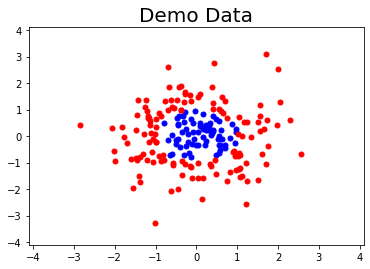

In [3]:
dim = 2
N = 200

np.random.seed(21) #for consistent result in testing

test_data, test_label = random_data(dim, N)

plot_data(test_data, test_label)

# ADABoost Helper functions 

In [3]:
def calculate_decision_stump(data, weights, labels):
    """
    Calculate the best decision stump for a given feature.
    
    Args:
    data : Dataset containing just as single feature
    weights: Sample weights
    labels: Sample class labels
    
    Returns:
    tuple: (best_threshold, best_direction, min_error)
    """
    data = pd.DataFrame(data)
    min_error = float('inf')
    best_thresh = 0
    best_dir = 0
    
    # Calculate thresholds
    feature_min = data.min().iloc[0]
    feature_max = data.max().iloc[0]
    #print("Min: ", feature_min, "max: ", feature_max)
    interval = (feature_max - feature_min) / 100.0                   #could optimise thresholds. 
    #print("INTERVAL: ", interval)
    thresholds = pd.interval_range(start=feature_min-interval*2, end=feature_max+interval*2, freq=interval) 
    #print(thresholds)
    
    for direction in [1, -1]:
        for thresh in thresholds:
            if direction == 1:
                predictions = (data >= thresh.left).astype(int) * 2 - 1 #this transforms the values from {0, 1} to {-1, 1}. Specifically, 1 remains 1, and 0 becomes -1.
            else:
                predictions = (data < thresh.left).astype(int) * 2 - 1 #this transforms the values from {0, 1} to {-1, 1}. Specifically, 1 remains 1, and 0 becomes -1.
           # print("PREDICTIONS ", [thresh], ": ", predictions, """""")
            # Calculate misclassifications          
            misclassifications = (predictions.iloc[:,0] != labels).astype(int)
            #print("MISSCLAS: ", misclassifications, """""")
            # Calculate weighted error
            weighted_error = (misclassifications * weights).sum()
            #print("WEIGHTED_ERROR: ", weighted_error, """""")
            if weighted_error < min_error:     
                min_error = weighted_error
                best_thresh = thresh.left
                best_dir = direction    
    
    return best_thresh, best_dir, min_error

In [4]:
def calculate_alpha(weighted_error):    
        return 0.5 *np.log((1-weighted_error)/ weighted_error)
    
def classify_dataset_against_weak_classifier(x, thresh, direction):
    
    classification = np.zeros(len(x))
    
    #classifiy all samples based on the last feature
    #get actual classification
    for i in range(len(x)):   
        if direction == -1:
            if x[i] < thresh:
                classification[i] = 1
            else: 
                classification[i] = -1
 
        else:
            if x[i] > thresh:
                    classification[i] = 1
            else: 
                classification[i] = -1  
                
    return classification 

In [5]:
def update_weights(weight, alpha, classification, label):

    for i in range(len(weight)):
        weight[i] =  weight[i] * np.exp(-1.0 * alpha.item() * classification[i] * label[i])

    return weight

def normalise_weights(weight):
    weight = weight/np.sum(weight)
    return weight 

In [6]:
def classify_sample(xi, boost_classif):
    boost_classif = boost_classif.values
    classification_sum = np.float64(0)
    
    for thresh, feat, sign, alpha, error in boost_classif:
        
        ht = np.sign(xi[int(feat)] - thresh) * sign
        classification_sum += alpha * ht
        
    if classification_sum >= 0:
        return 1
    else:
        return -1
    
def fit_Adaboost(eval_data, classifier_df, fit_df):
    fitted_df = pd.DataFrame(columns = ['Fit'])
    error = np.sum(fit_df.classification != fit_df.true_class_label) / len(fit_df)
    
    for i in range(len(eval_data)):
        x = classify_sample(eval_data[i], classifier_df)
        fitted_df = fitted_df.append({"Fit": x}, ignore_index=True)
        
        if x == 1:
            plt.plot([eval_data[i,0]],[eval_data[i,1]], 'bo', markersize=5)
        else:
            plt.plot(eval_data[i,0],eval_data[i,1], 'ro', markersize=5)
    
    plt.suptitle("Classified Evaluation Dataset", size=20)
    plt.title(f'Trained model error = {error}', size=10, pad=5)
        
    return fitted_df


def sum_classifier_votes_for_each_sample(dataset, df, classifier_df):
    for i in range(len(dataset)):
        classification_sum = np.float64(0)
        neg_votes = np.float64(0)
        pos_votes = np.float64(0)
        for idx, thresh, feat, sign, alpha in classifier_df.itertuples():
             
            ht = np.sign(dataset[i, int(feat)] - thresh) * sign
            classification_sum += alpha * ht
            if ht < 0:
                neg_votes += alpha * ht
            else:
                pos_votes += alpha * ht

        df['sum_alpha'].iloc[i] = classification_sum
        df['pos_votes'].iloc[i] = pos_votes
        df['neg_votes'].iloc[i] = neg_votes
    
    return df

In [7]:
def margin_calculation(sign, pos, neg, tot_votes):
       
    if np.sign(sign) < 0:
        return np.abs(neg) / tot_votes, -1
    else:
        return pos / tot_votes, 1 

def sign_of_margin(margin, classification, true_class_label):  
    return margin * classification * true_class_label
    

#  ADABoost algorithm

In [8]:
def Adaboost (T, data, label):
    N=data.shape[0]
    dim = data.shape[1]
    h = np.zeros([T, 3], dtype=np.float64)
    #print(h)
    alpha = np.zeros(T, dtype=np.float64)
    weight = ((pd.Series([1]*N))/N).values
    err = np.ones(T, dtype=np.float64) * np.inf
    
    #0 - for each boosting round
    for t in range(T):
        #1 - iterate through every feature  
        for feature in range(dim):
            weighted_error = np.float64(0)

            #========================
            #2 - GENERATE A DECISION STUMP FOR A FEATURE
            #========================
            threshold, sign, weighted_error = calculate_decision_stump(data[:,feature], weight, label)
            #returns best_thresh, best_dir, min_error

            #========================
            #3 - KEEP TRACK OF THE FEATURE WITH THE LOWEST WEIGHTED ERROR
            #========================   

            if weighted_error < err[t] : 
                err[t] = weighted_error         
                h[t] = [threshold, feature, sign]

        #========================
        #4 - CALCULATE ALPHA FOR BOOSTING ROUND t
        #========================            
        alpha[t] = calculate_alpha(err[t])
        #returns alpha as a value

        #========================
        #5 - CLASSIFY ALL SAMPLES BASED ON THE SELECTED FEATURE FOR BOOSTING ROUND t
        #========================
        classification = classify_dataset_against_weak_classifier(data[:,h[t][1].astype(int)], h[t][0], h[t][2])
        #returns classification as array

        #========================
        #6 - UPDATE WEIGHTS BASED ON THE CORRECTNESS OF THE CLASSIFICATION
        #========================   
        weight = update_weights(weight, alpha[t], classification, label)
        #returns weight as an array

        #========================
        #7 - NORMALISE REASSIGNED WEIGHTS
        #========================  
        weight = normalise_weights(weight)
        #returns weight as array 

        #--------------------------------------------
        #BOOSTING ALGORITHM DONE, NOW CREATE OUTPUT DATAFRAMES
        #--------------------------------------------
    classifier_df = pd.DataFrame(h, columns = ["threshold", "feature", "direction"])
    classifier_df["alpha"] = alpha
        
    training_set_df = pd.DataFrame(data)
    training_set_df['sum_alpha'] = 0 
    training_set_df['pos_votes'] = 0 
    training_set_df['neg_votes'] = 0 

    training_set_df = sum_classifier_votes_for_each_sample(data, training_set_df, classifier_df)
    total_alpha_votes = np.sum(classifier_df.alpha)
    training_set_df['classification'] = 0
    training_set_df['margin'] = 0
    training_set_df['total_alpha_votes'] = total_alpha_votes
    result = training_set_df[['sum_alpha','pos_votes','neg_votes','total_alpha_votes']].apply(lambda data: margin_calculation(*data), axis=1)
    training_set_df['margin'] = result.apply(lambda data: data[0])
    training_set_df['classification'] = result.apply(lambda data: data[1])
    training_set_df['true_class_label'] = label
    training_set_df['sign_of_margin'] = training_set_df[['margin', 'classification', 'true_class_label']].apply(lambda data: sign_of_margin(*data), axis=1)

    classifier_df["error"] = err
    
    print("Classification of ", T, " iterations complete")
    
    return classifier_df, training_set_df 

# Kaggle loan data

In [9]:
df=pd.read_csv('train.csv')
dftest=pd.read_csv('test.csv')

In [10]:
#remove impossible values (can't be employed for more than your life... I hope)
df.drop((df[df['person_age'] <= df["person_emp_length"]].index))

#change label for Adaboost
df['loan_status'].replace(0, -1, inplace = True)

#make label dataset
df_label = np.array(df["loan_status"])

#change {Y, N} values to {1, 0}
df['cb_person_default_on_file'].replace({'Y': 1, 'N': 0}, inplace = True)
df['loan_grade'].replace({'A': 6, 'B': 5, 'C': 4, 'D': 3,'E': 2, 'F': 1, 'G': 0}, inplace = True)

#encode categorical variables
df = df.join(pd.get_dummies(df['person_home_ownership']))
df = df.join(pd.get_dummies(df['loan_intent']))

#remove unnecessary data
df.drop(['id', 'loan_status', 'loan_intent', 'person_home_ownership'], axis=1, inplace=True)

df

,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,MORTGAGE,OTHER,OWN,RENT,DEBTCONSOLIDATION,EDUCATION,HOMEIMPROVEMENT,MEDICAL,PERSONAL,VENTURE
0,37,35000,0.0,5,6000,11.49,0.17,0,14,0,0,0,1,0,1,0,0,0,0
1,22,56000,6.0,4,4000,13.35,0.07,0,2,0,0,1,0,0,0,0,1,0,0
2,29,28800,8.0,6,6000,8.90,0.21,0,10,0,0,1,0,0,0,0,0,1,0
3,30,70000,14.0,5,12000,11.11,0.17,0,5,0,0,0,1,0,0,0,0,0,1
4,22,60000,2.0,6,6000,6.92,0.10,0,3,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58640,34,120000,5.0,3,25000,15.95,0.21,1,10,1,0,0,0,0,1,0,0,0,0
58641,28,28800,0.0,4,10000,12.73,0.35,0,8,0,0,0,1,0,0,0,1,0,0
58642,23,44000,7.0,3,6800,16.00,0.15,0,2,0,0,0,1,0,1,0,0,0,0
58643,22,30000,2.0,6,5000,8.90,0.17,0,3,0,0,0,1,0,1,0,0,0,0


In [103]:
df_train = np.array(df)

In [110]:
cdf_1, rdf_1 = Adaboost(1, df_train, df_label)
cdf_10, rdf_10 = Adaboost(10, df_train, df_label)
cdf_30, rdf_30 = Adaboost(30, df_train, df_label)
cdf_50, rdf_50 = Adaboost(50, df_train, df_label)
cdf_100, rdf_100 = Adaboost(100, df_train, df_label)

In [114]:
error_1 = sum(rdf_1['classification'] == rdf_1['true_class_label'])/ len(df_label)
error_10 = sum(rdf_10['classification'] == rdf_10['true_class_label'])/ len(df_label)
error_30 = sum(rdf_30['classification'] == rdf_30['true_class_label'])/ len(df_label)
error_50 = sum(rdf_50['classification'] == rdf_50['true_class_label'])/ len(df_label)
error_100 = sum(rdf_100['classification'] == rdf_100['true_class_label'])/ len(df_label)
print("Error 1: ", error_1, "\nError 10: ", error_10, "\nError 30: ", error_30, "\nError 50: ", error_50, "\nError 100: ", error_100)


Error 1:  0.8893341290817631 
Error 10:  0.9233523744564754 
Error 30:  0.9258419302583341 
Error 50:  0.9259783442748742 
Error 100:  0.9268650353823855


In [115]:
cdf_100

,threshold,feature,direction,alpha,error
0,0.301892,6.0,1.0,1.041979,0.110666
1,3.030291,3.0,-1.0,0.624272,0.222952
2,0.010000,12.0,1.0,0.384955,0.316498
3,11.116000,5.0,1.0,0.246636,0.379123
4,0.010000,18.0,-1.0,0.140793,0.430065
...,...,...,...,...,...
95,7745.000000,4.0,-1.0,0.012152,0.493924
96,42116.000000,1.0,1.0,0.012672,0.493664
97,0.251604,6.0,1.0,0.013786,0.493108
98,0.293511,6.0,-1.0,0.012749,0.493626
